In [1]:
import sys
sys.path.append("/hlabhome/wg-mjames/git/Toby_work")
import pandas as pd
import numpy as np
import elephant
from scipy import stats,signal,integrate
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn import metrics, preprocessing
from sklearn.feature_selection import RFE
import imblearn
from imblearn import over_sampling
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import ks_2samp
import pickle
import random
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from graphical_functions import *
from helper_functions_math_addons import *
from helper_functions_file_handling import *
from helper_functions_modeling import *
from sklearn.utils.class_weight import compute_sample_weight
from collections import Counter
from threadpoolctl import threadpool_info, threadpool_limits
%load_ext autoreload
%autoreload 2
import os
NCPU = "4"
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
os.environ['VECLIB_MAXIMUM_THREADS'] = '4'
os.environ['NUMEXPR_NUM_THREADS'] = '4'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.family':'DejaVu Sans'})

In [2]:
#Quick load an already scaled dataset for ease
split_thres = (0.4, 0.6)
addon = 'unfiltered'
downlims = [5,3,5]
load_data=True
train_scaled, test_scaled = obtain_train_test_scaled_data(split_thres, addon, load_data, 
                                                          downlims)

Loaded successfully


In [4]:
#Ignore its train/test split and just recombine it so we can do our own thing
reversal_to_full = pd.concat([train_scaled, test_scaled])
condensed_dataframe = get_extended_condensed_data(reversal_to_full)

In [5]:
condensed_dataframe

,index,state,region,cell,animal,celltype,geno,cell_no,age,age_group,state_str,cell_state,state_chunks
0,0,2,ACad,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,2,caf69_358_1228_0_12_0_wt-2,537
1,367,0,ACad,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,0,caf69_358_1228_0_12_0_wt-0,199
2,524,1,ACad,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,1,caf69_358_1228_0_12_0_wt-1,55
3,561,2,ACad,caf69_358_1228_0_12_1_wt,caf69,RSU,wt,1,358,old,2,caf69_358_1228_0_12_1_wt-2,94
4,627,0,ACad,caf69_358_1228_0_12_1_wt,caf69,RSU,wt,1,358,old,0,caf69_358_1228_0_12_1_wt-0,59
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12945,1824735,2,V1,bth100_99_0624_12_24_94_wt,bth100,RSU,wt,94,99,young,2,bth100_99_0624_12_24_94_wt-2,1241
12946,1825567,0,V1,bth100_99_0624_12_24_94_wt,bth100,RSU,wt,94,99,young,0,bth100_99_0624_12_24_94_wt-0,216
12947,1825748,1,V1,bth100_99_0624_12_24_94_wt,bth100,RSU,wt,94,99,young,1,bth100_99_0624_12_24_94_wt-1,33
12948,408415,1,ACad,zbr119_112_0604_0_12_75_app_ps1,zbr119,RSU,app_ps1,75,112,young,1,zbr119_112_0604_0_12_75_app_ps1-1,1


In [6]:
#Create a condensed dataframe counting up all of the relevant data per animal
animals = condensed_dataframe.animal.unique()
output = {'animal':[], 'geno':[], 'age':[], 'age_group':[], 'sum_chunks':[],'chunks':[], 'unit_count':[]}
for animal in animals:
    data = condensed_dataframe[condensed_dataframe.animal==animal]
    output['animal'].append(animal)
    output['geno'].append(data.iloc[0].geno)
    output['age'].append(data.iloc[0].age)
    output['age_group'].append(data.iloc[0].age_group)
    output['unit_count'].append(len(data.drop(columns=['state', 'state_str', 'cell_state', 
                                                       'state_chunks','index']).drop_duplicates()))
    chunks = [[],[],[]]
    sum_chunks = [0,0,0]
    for i, row in data.iterrows():
        chunks[row.state].append(row.state_chunks)
        sum_chunks[row.state] += row.state_chunks
    output['chunks'].append(chunks)
    output['sum_chunks'].append(sum_chunks)
df = pd.DataFrame(output)

In [7]:
df

,animal,geno,age,age_group,sum_chunks,chunks,unit_count
0,caf69,wt,358,old,"[108444, 21244, 104313]","[[199, 59, 63, 65, 62, 78, 61, 126, 199, 83, 8...",366
1,caf71,app_ps1,492,old,"[60581, 1659, 35141]","[[122, 181, 205, 195, 179, 328, 198, 131, 166,...",248
2,caf73,app_ps1,381,old,"[152900, 8475, 50362]","[[113, 205, 794, 478, 635, 674, 307, 281, 212,...",389
3,caf74,app_ps1,419,old,"[97297, 1925, 60293]","[[399, 251, 126, 147, 314, 383, 813, 388, 250,...",289
4,caf75,app_ps1,389,old,"[67096, 3068, 57185]","[[815, 306, 162, 726, 1769, 277, 85, 252, 67, ...",309
5,caf77,wt,394,old,"[32964, 6729, 30492]","[[441, 463, 93, 649, 377, 101, 276, 178, 212, ...",112
6,caf81,wt,455,old,"[92061, 25413, 105843]","[[211, 150, 90, 171, 397, 75, 87, 270, 119, 15...",423
7,caf82,wt,455,old,"[81495, 14513, 66498]","[[1585, 635, 351, 144, 157, 777, 925, 864, 142...",210
8,zbr106,wt,101,young,"[55262, 12533, 94664]","[[119, 613, 284, 68, 177, 193, 1201, 88, 363, ...",242
9,zbr113,app_ps1,91,young,"[3653, 757, 21263]","[[60, 77, 105, 32, 208, 21, 18, 151, 159, 168,...",38


In [8]:
#Recursive permutations by group method, not sure why I bothered making this but it was sort of interesting
def permutations(*groups):
    result = []
    if len(groups)==1:
        return [[i] for i in groups[0]]
    base_groups = permutations(*groups[1:])
    for i, val in enumerate(groups[0]):
        for ind, li in enumerate(base_groups):
            addon = [val, *li]
            result.append(addon)
    return result

In [9]:
#Get an ordered list of animals according to age and genome for convenience
animal_ordered = []
for animal in df[(df.geno=='wt')&(df.age_group=='young')].animal.unique():
    animal_ordered.append(animal)
for animal in df[(df.geno=='app_ps1')&(df.age_group=='young')].animal.unique():
    animal_ordered.append(animal)
for animal in df[(df.geno=='wt')&(df.age_group=='old')].animal.unique():
    animal_ordered.append(animal)
for animal in df[(df.geno=='app_ps1')&(df.age_group=='old')].animal.unique():
    animal_ordered.append(animal)
animal_ordered.remove('zbr113')

In [10]:
from copy import deepcopy

#Get all possible permutations
init_permut = permutations([0,1,2,3],[4,5,6,7],[8,9,10,11],[12,13,14,15])
total_options = []
for permut in tqdm(init_permut):
    first_pick = permut
    this_use = [[0,1,2,3],[4,5,6,7],[8,9,10,11],[12,13,14,15]]
    for i in range(4):
        this_use[i].remove(first_pick[i])
    options_here = permutations(*this_use)
    for option in options_here:
        initial_case = deepcopy(this_use[:])
        for i in range(4):
            initial_case[i].remove(option[i])
        options_now = permutations(*initial_case)
        for third_pick in options_now:
            third_case = deepcopy(initial_case)
            for i in range(4):
                third_case[i].remove(third_pick[i])
            options_third = permutations(*third_case)
            total_options.append([permut, option, third_pick, options_third[0]])
        

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 256/256 [00:04<00:00, 52.03it/s]


In [44]:
#Dictate what you are balancing for
animal_to_units = {}
for animal in df.animal:
    #Change this line to the specific thing you want to be the "balance factor" for every layout going forward. In this
    #case it is using the total number of sleep chunks in the animal
    animal_to_units[animal] = sum(df[df.animal==animal].sum_chunks.iloc[0])

In [45]:
#Double check this is mapping the value you want
animal_to_units

{'caf69': 234001,
 'caf71': 97381,
 'caf73': 211737,
 'caf74': 159515,
 'caf75': 127349,
 'caf77': 70185,
 'caf81': 223317,
 'caf82': 162506,
 'zbr106': 162459,
 'zbr113': 25673,
 'zbr114': 97449,
 'zbr117': 109151,
 'zbr118': 117130,
 'zbr119': 115856,
 'bth90': 145295,
 'bth95': 133611,
 'bth100': 136056}

In [20]:
#Calculate the balance for a single grouping, based on means squared error (I believe)
def calculate_balance_for_group(grouping, animal_to_units, animal_ordered):
    vals = []
    for group in grouping:
        vals.append(np.average([animal_to_units[animal_ordered[group[i]]] for i in range(len(group))]))
    min_ind = vals.index(min(vals))
    
    #Add in zbr113 to smallest grouping as tacked on guy, guarantees that zbr113 added to minimal group will minimize error
    vals[min_ind] = (vals[min_ind]*4 + animal_to_units['zbr113'])/5
    total_avg = np.average(vals)
    distance = sum([abs(vals[i]-total_avg)**2 for i in range(4)])
    return distance, min_ind

In [24]:
#Get all balancing values for every single permutation option
def get_balancing_for_animal_groupings(total_options, animal_to_units, animal_ordered):
    results = {'grouping':[], 'balance':[], 'tack_on_ind':[], 'to_animal':[]}
    for layout in tqdm(total_options):
        bal, min_ind = calculate_balance_for_group(layout, animal_to_units, animal_ordered)
        results['grouping'].append(layout)
        results['balance'].append(bal)
        results['tack_on_ind'].append(min_ind)
        animal_layout = []
        for group in layout:
            animal_layout.append([animal_ordered[group[i]] for i in range(len(group))])
        animal_layout[min_ind].append('zbr113')
        results['to_animal'].append(animal_layout)
    results = pd.DataFrame(results)
    return results

In [46]:
#Actually get those balancing results
results = get_balancing_for_animal_groupings(total_options, animal_to_units, animal_ordered)
display(results)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 331776/331776 [00:12<00:00, 25992.67it/s]


,grouping,balance,tack_on_ind,to_animal
0,"[[0, 4, 8, 12], [1, 5, 9, 13], [2, 6, 10, 14],...",1.172784e+09,1,"[[zbr106, zbr114, caf69, caf71], [bth90, zbr11..."
1,"[[0, 4, 8, 12], [1, 5, 9, 13], [2, 6, 10, 15],...",9.329867e+08,1,"[[zbr106, zbr114, caf69, caf71], [bth90, zbr11..."
2,"[[0, 4, 8, 12], [1, 5, 9, 13], [2, 6, 11, 14],...",9.371796e+08,1,"[[zbr106, zbr114, caf69, caf71], [bth90, zbr11..."
3,"[[0, 4, 8, 12], [1, 5, 9, 13], [2, 6, 11, 15],...",1.186394e+09,1,"[[zbr106, zbr114, caf69, caf71], [bth90, zbr11..."
4,"[[0, 4, 8, 12], [1, 5, 9, 13], [2, 7, 10, 14],...",1.158367e+09,1,"[[zbr106, zbr114, caf69, caf71], [bth90, zbr11..."
...,...,...,...,...
331771,"[[3, 7, 11, 15], [2, 6, 10, 14], [1, 4, 9, 13]...",1.363392e+09,2,"[[bth100, zbr119, caf82, caf75], [bth95, zbr11..."
331772,"[[3, 7, 11, 15], [2, 6, 10, 14], [1, 5, 8, 12]...",1.093902e+09,0,"[[bth100, zbr119, caf82, caf75, zbr113], [bth9..."
331773,"[[3, 7, 11, 15], [2, 6, 10, 14], [1, 5, 8, 13]...",4.024708e+09,3,"[[bth100, zbr119, caf82, caf75], [bth95, zbr11..."
331774,"[[3, 7, 11, 15], [2, 6, 10, 14], [1, 5, 9, 12]...",4.231389e+09,2,"[[bth100, zbr119, caf82, caf75], [bth95, zbr11..."


In [26]:
#Get the actual numbers of whatever value you were using per group (1080 neurons per for example)
def animal_layout_to_descriptive(layout):
    totals = []
    for row in layout:
        totals.append(sum([animal_to_units[row[i]] for i in range(len(row))]))
    return totals
#Check that the layout you have actually works in terms of having one from each geno/age grouping
def check_layout_for_legal(layout):
    for row in layout:
        wy, wo, ay, ao = 0,0,0,0
        for animal in row:
            if (df[df.animal==animal].geno.iloc[0]=='wt') and (df[df.animal==animal].age_group.iloc[0]=='young'):
                wy+=1
            elif (df[df.animal==animal].geno.iloc[0]=='app_ps1' and df[df.animal==animal].age_group.iloc[0]=='old'):
                ao+=1
            elif df[df.animal==animal].geno.iloc[0]=='wt' and df[df.animal==animal].age_group.iloc[0]=='old':
                wo+=1
            else: 
                if animal != "zbr113":
                    ay += 1
        if not (wy==wo==ay==ao): return False
    return True

In [31]:
#Do all train/test combos (testing on the validation set technically, leaving the test set out)
def train_test_val_set_for_all_combos_in_layout(layout, condensed_df, full_df):
    combos = ([0, 1],[1,2], [2,3], [3, 0]) 
    use = condensed_df
    total_cms = {}
    for combo in combos:
        train_animals = [*layout[combo[0]], *layout[combo[1]]]
        train_cells = use[use['animal'].isin(train_animals)]['cell']
        test_cells = use[~use['animal'].isin(layout[(combo[1]+1)%4])]['cell']
        #print(test_cells, train_cells)
        train_scaled = full_df[full_df['cell'].isin(train_cells)]
        test_scaled = full_df[full_df['cell'].isin(test_cells)]
        #print(train_scaled, test_scaled)
        #break
        models = train_multi_models(train_scaled, sampling_types=['over'], methods=['LogRegGroup'])
        cms = get_cms_multi(test_scaled, models, get_spiking=False, include_timing=False)
        total_cms[f'Holding out Combo {combo}'] = cms['LogRegGroup_over']['all in total']
    return total_cms

In [47]:
best_layout = results[results.balance==min(results.balance)].to_animal.iloc[0]
display(best_layout)
display(animal_layout_to_descriptive(best_layout))
assert check_layout_for_legal(best_layout)


[['zbr106', 'zbr118', 'caf77', 'caf73', 'zbr113'],
 ['bth90', 'zbr119', 'caf82', 'caf74'],
 ['bth95', 'zbr114', 'caf81', 'caf75'],
 ['bth100', 'zbr117', 'caf69', 'caf71']]

[587184, 583172, 581726, 576589]

In [48]:
#Actually train them models and get their cms
res_cms = train_test_val_set_for_all_combos_in_layout(best_layout, condensed_dataframe, reversal_to_full)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.72it/s]


In [48]:
# base_set = set()
# for row in best_layout:
#     #print(row)
#     base_set.add(tuple(row))
# print(base_set)
# for row in results[results.balance==min(results.balance)].to_animal:
#     for inner_row in row:
#         if tuple(inner_row) not in base_set:
#             print(row)

{('bth90', 'zbr118', 'caf82', 'caf75'), ('bth100', 'zbr119', 'caf81', 'caf71'), ('zbr106', 'zbr114', 'caf69', 'caf74'), ('bth95', 'zbr117', 'caf77', 'caf73', 'zbr113')}


In [33]:
best_layout

[['zbr106', 'zbr118', 'caf77', 'caf73'],
 ['bth90', 'zbr119', 'caf69', 'caf71'],
 ['bth95', 'zbr117', 'caf82', 'caf75', 'zbr113'],
 ['bth100', 'zbr114', 'caf81', 'caf74']]

In [49]:
train_condensed = get_extended_condensed_data(reversal_to_full)

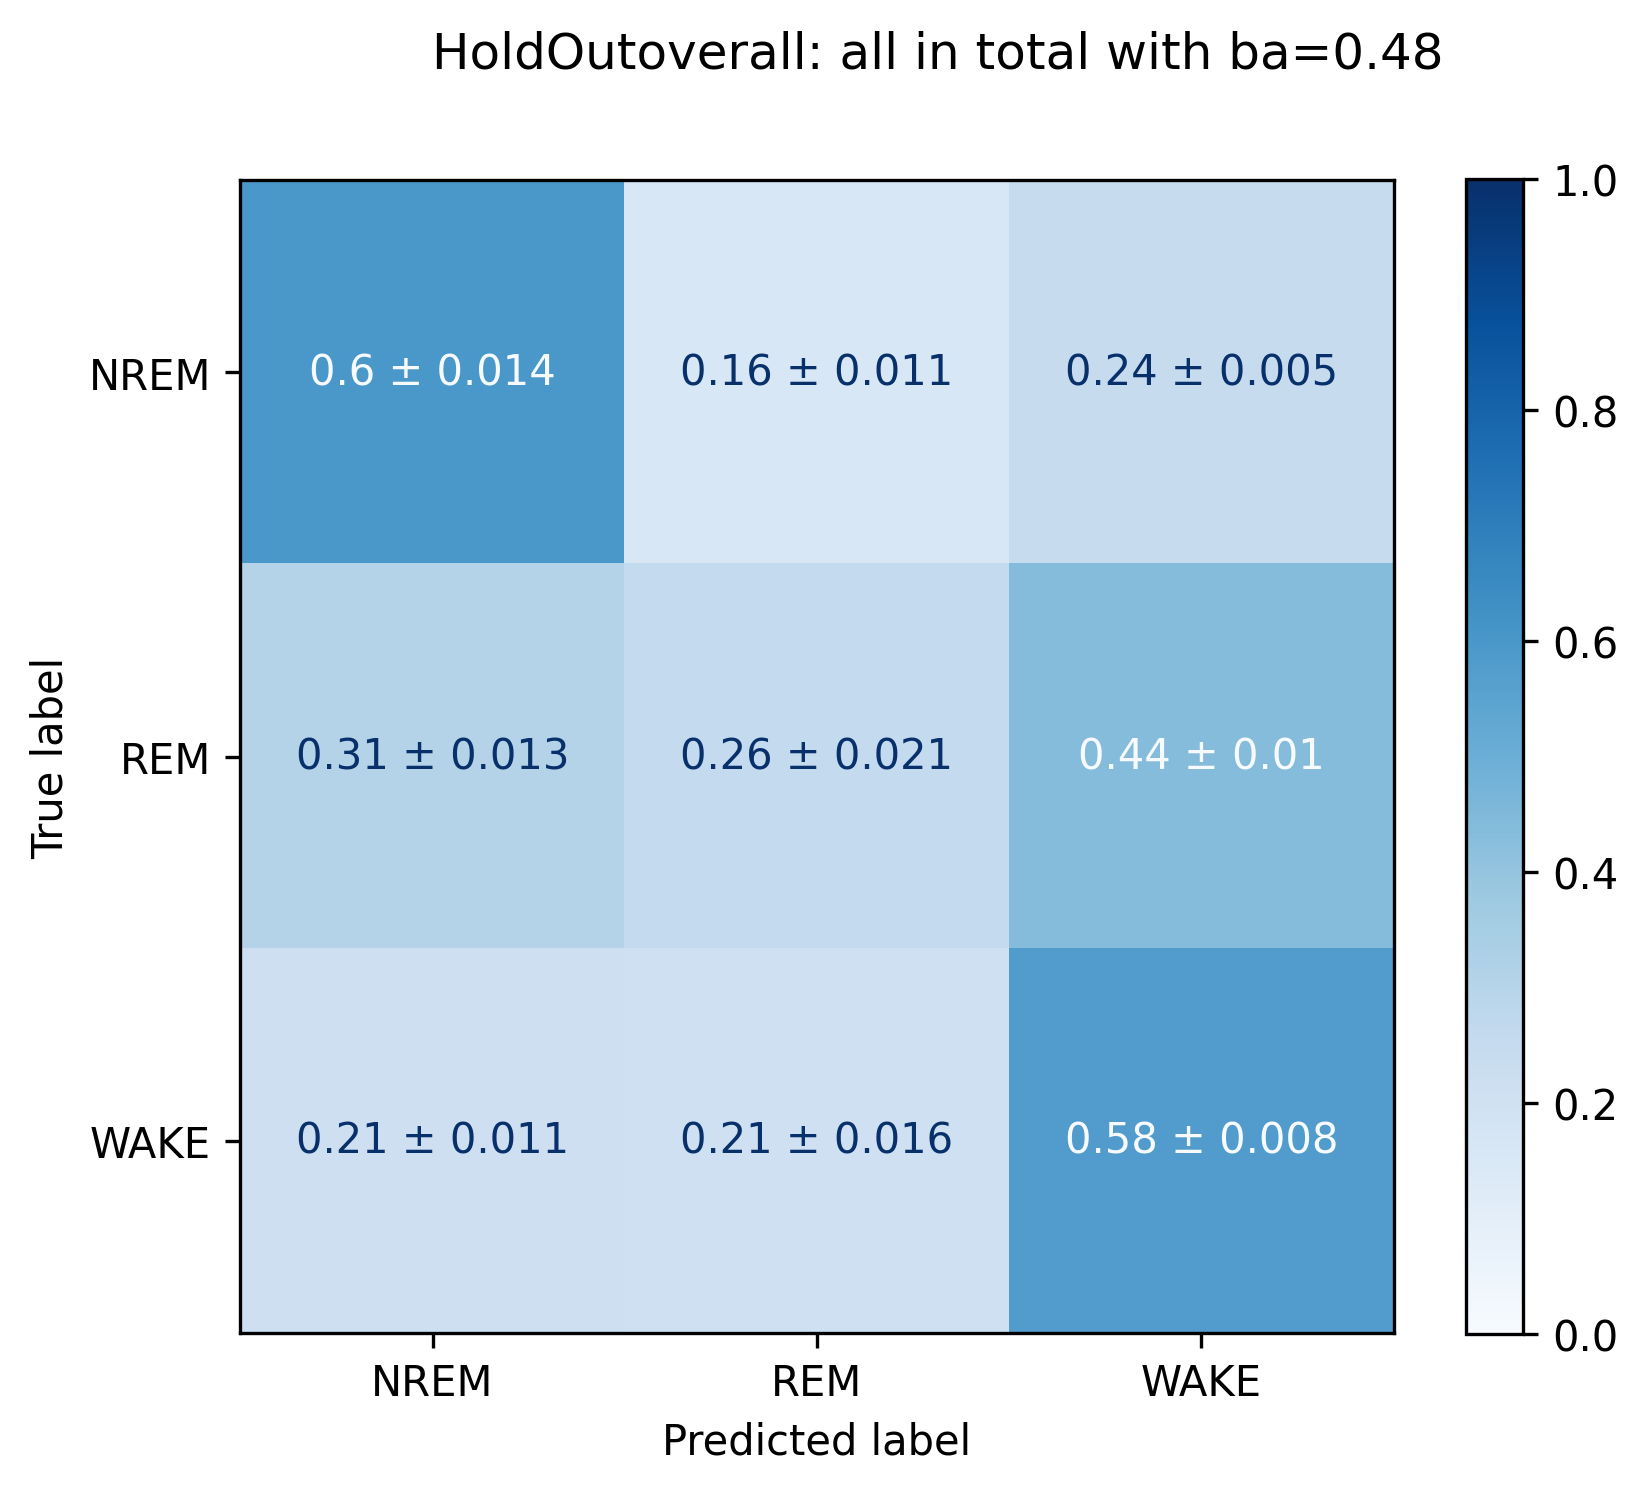

In [50]:
#Visualize average
for name, matrices in {"overall":res_cms}.items():
    get_mean_cms_visual(matrices, train_condensed, f"HoldOut{name}", subplot_kwargs={'figsize':(6.2,5), 'dpi':300}, 
                        addon_text=False, se=True, prev_group_by_anim=True)

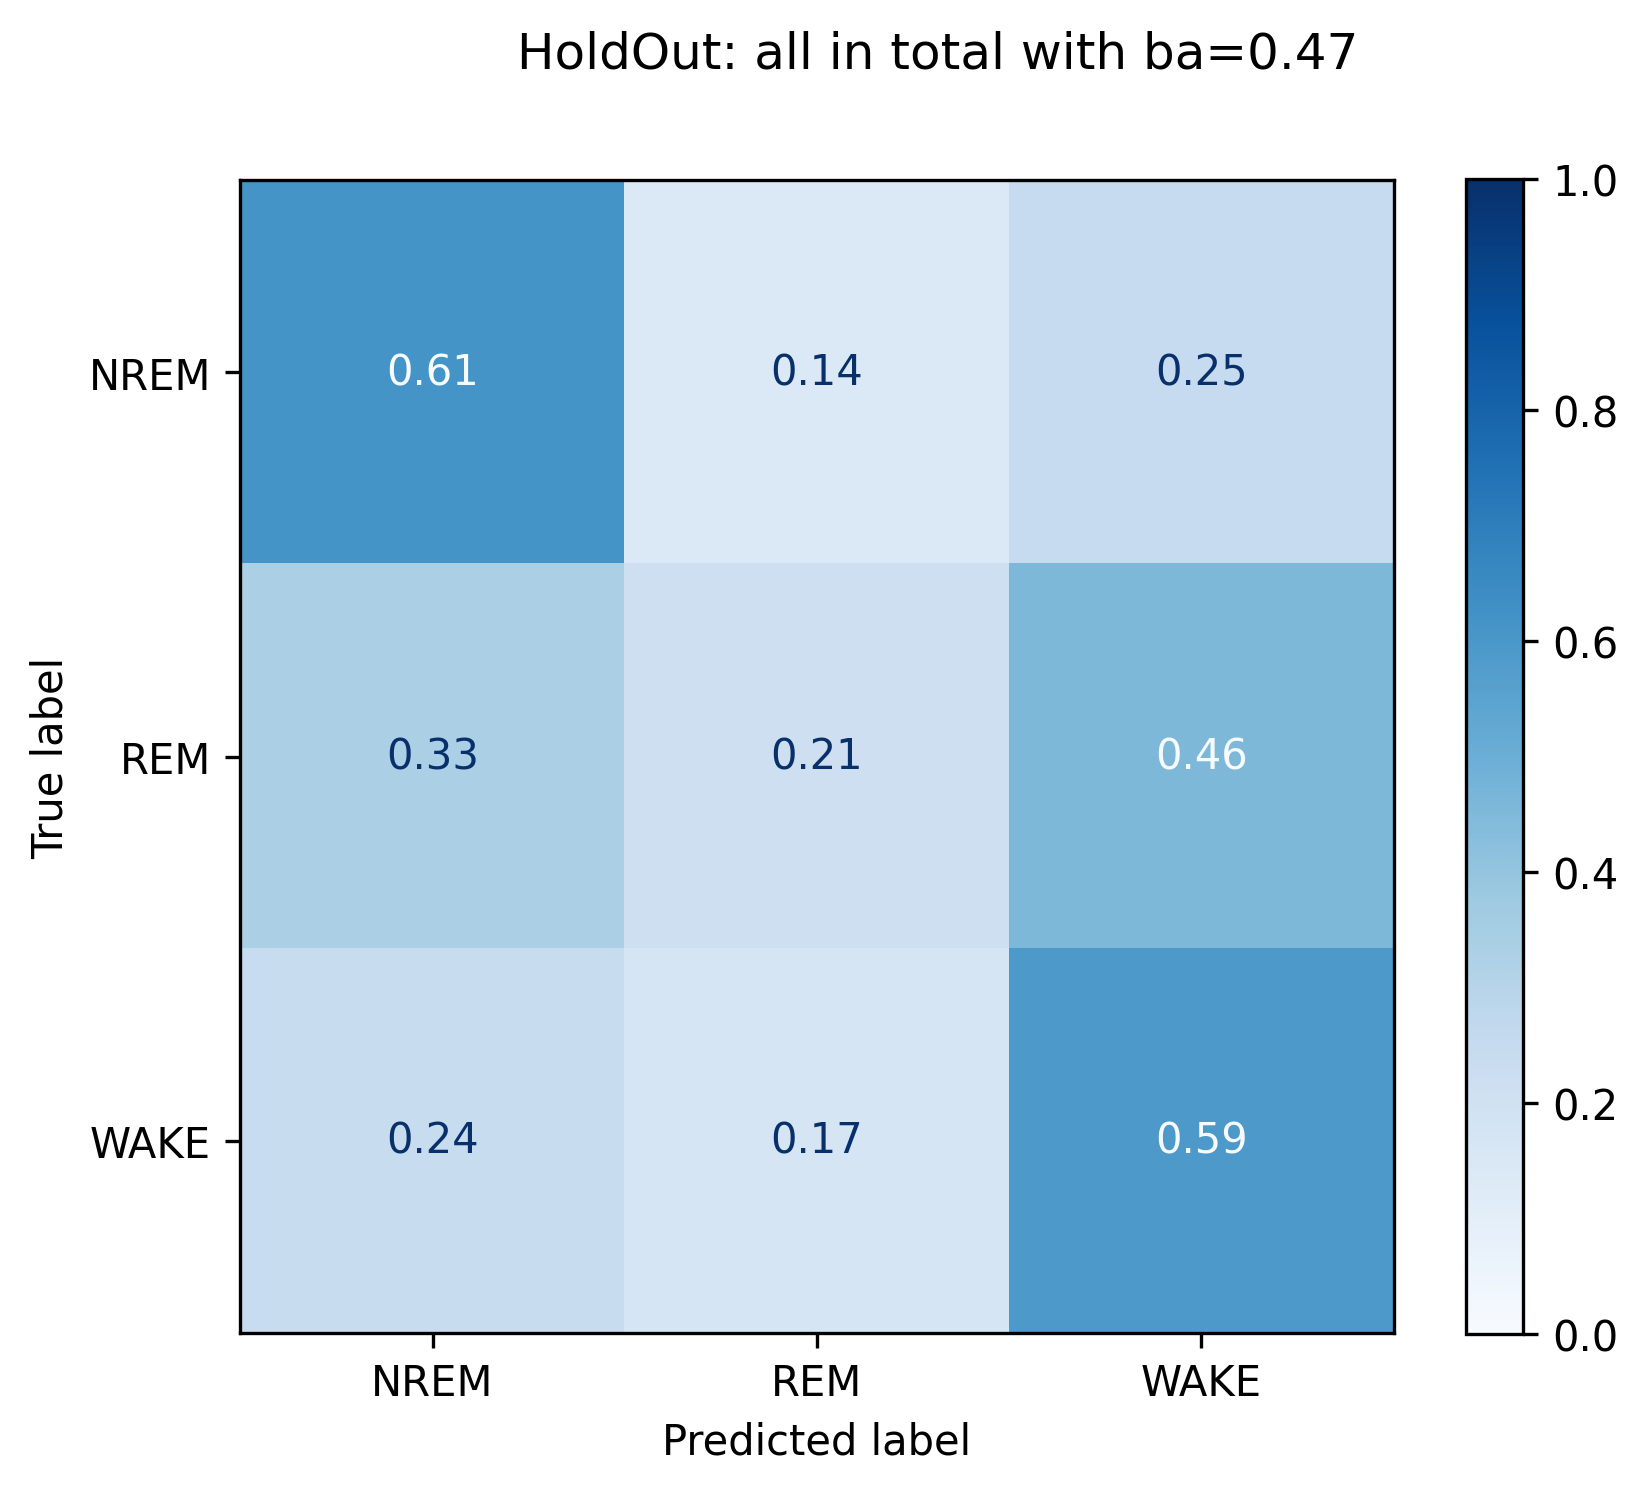

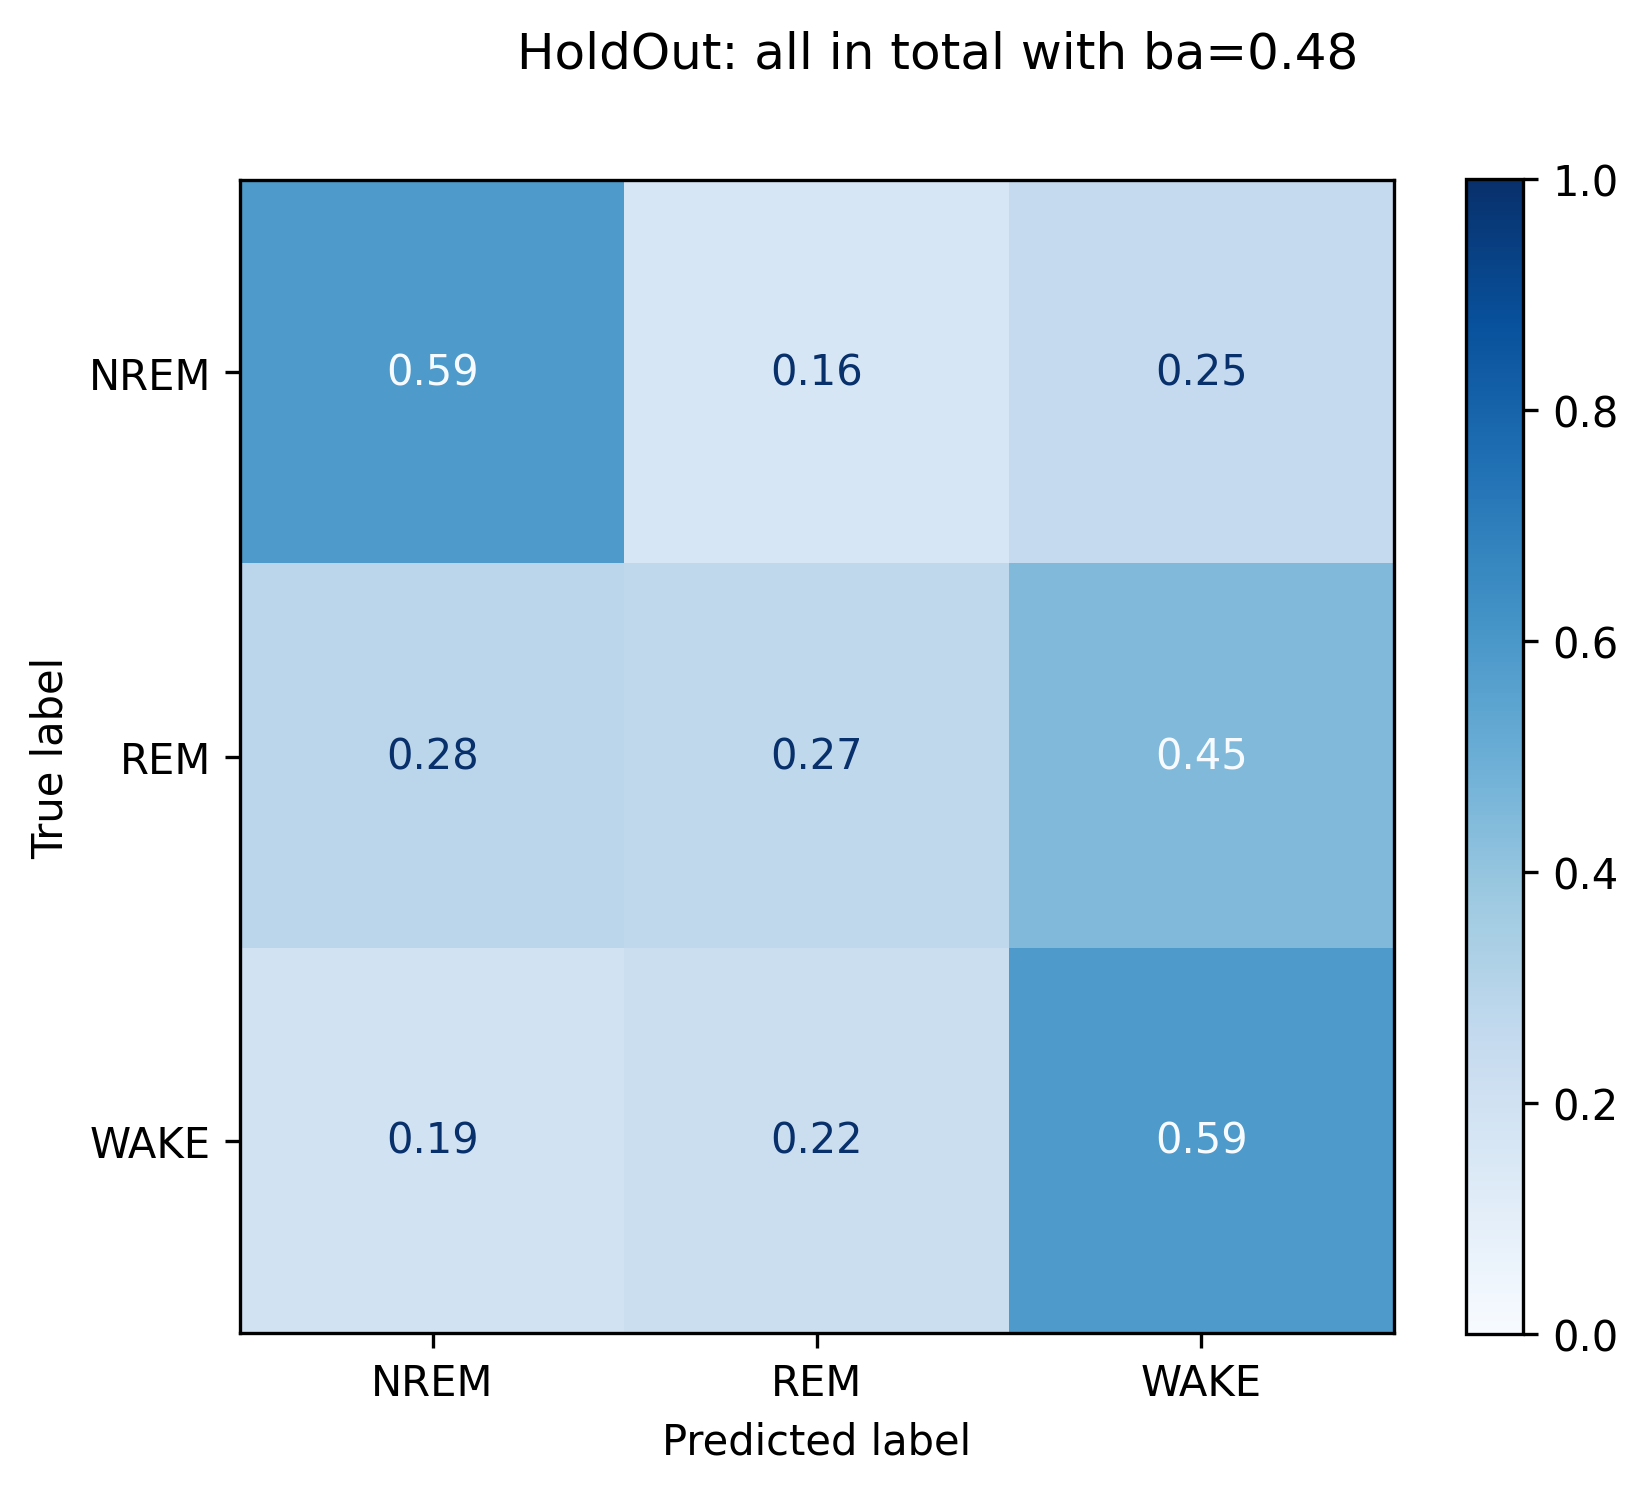

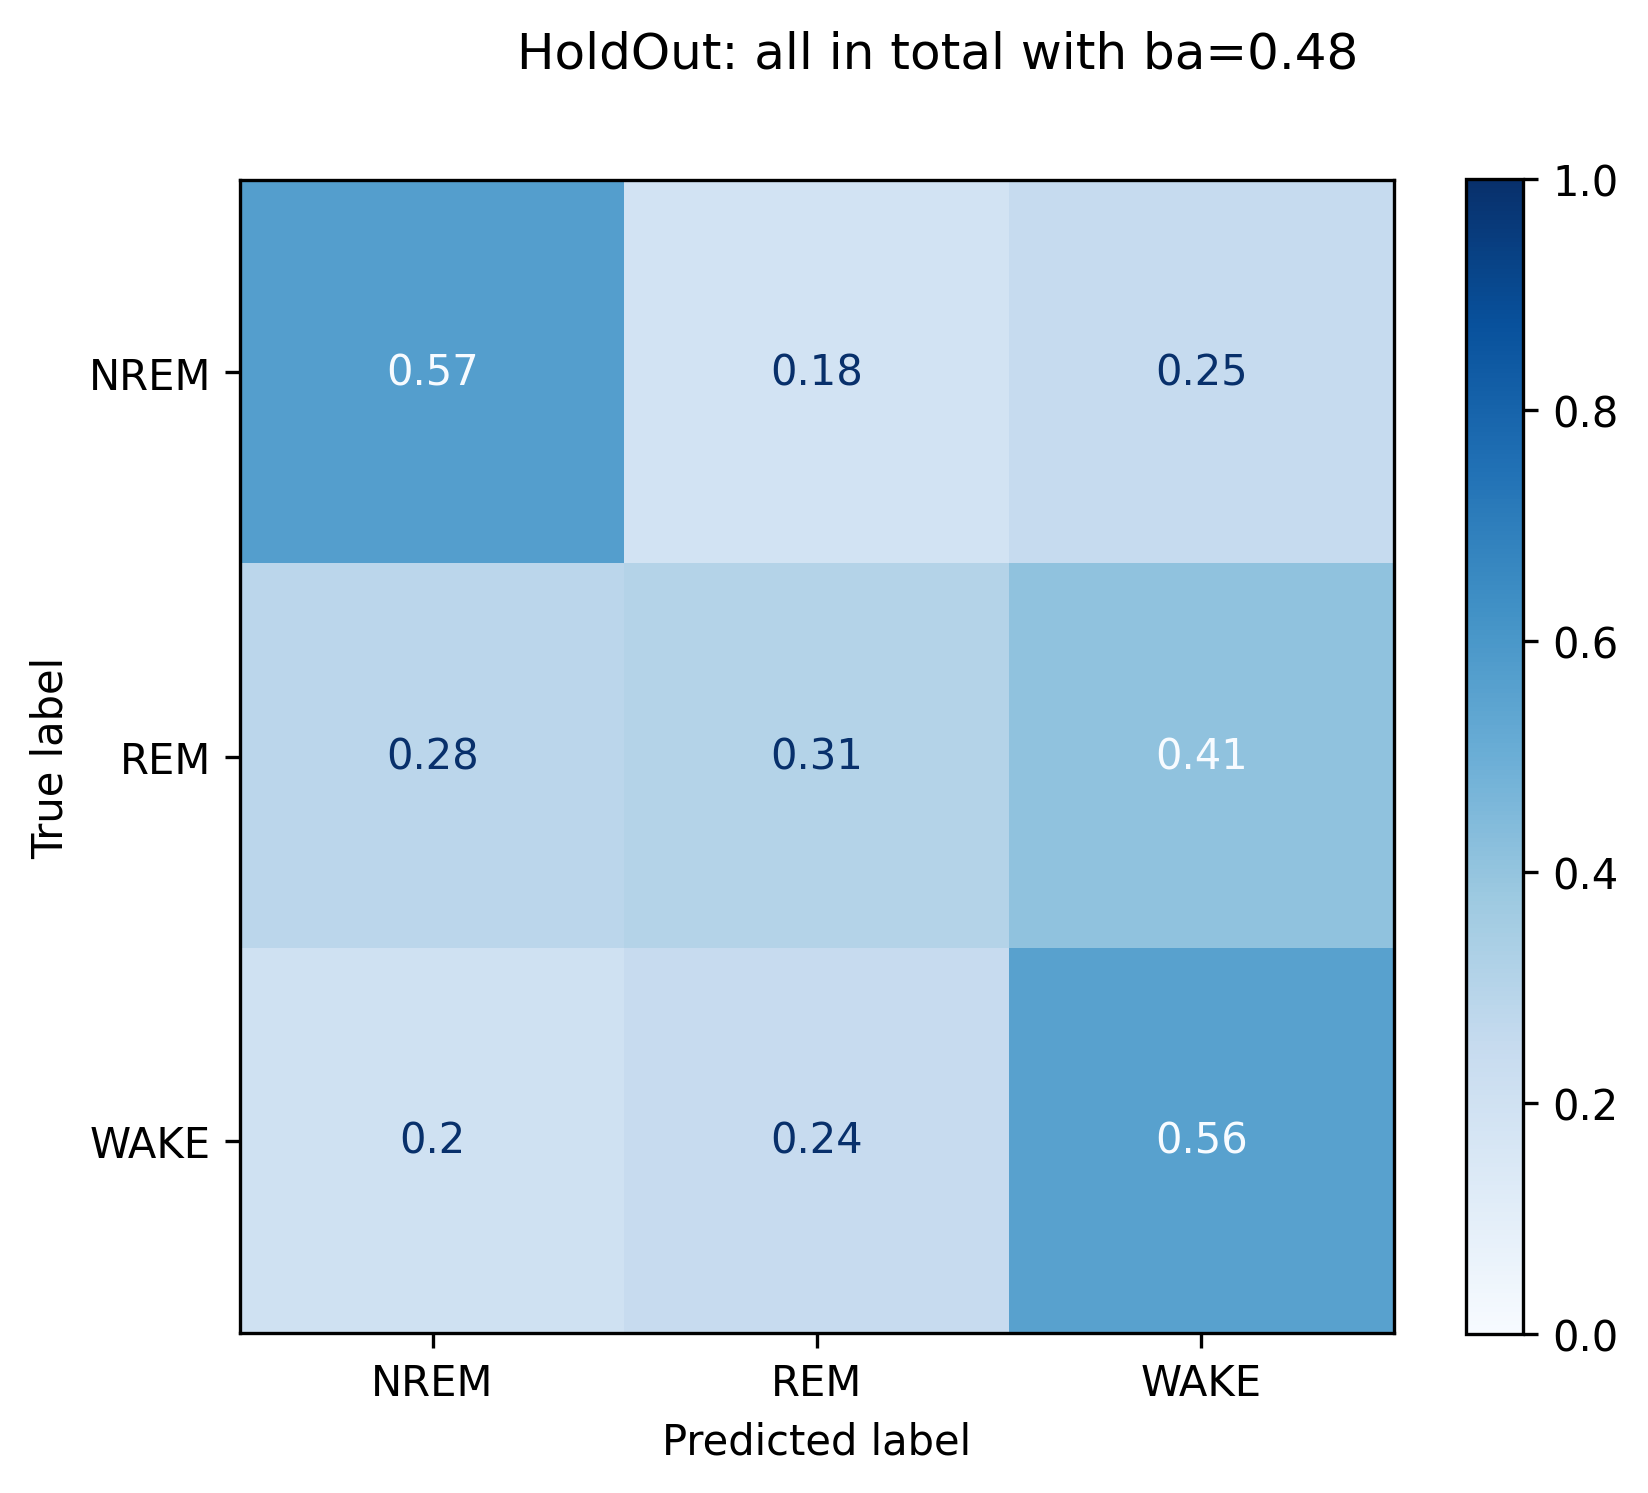

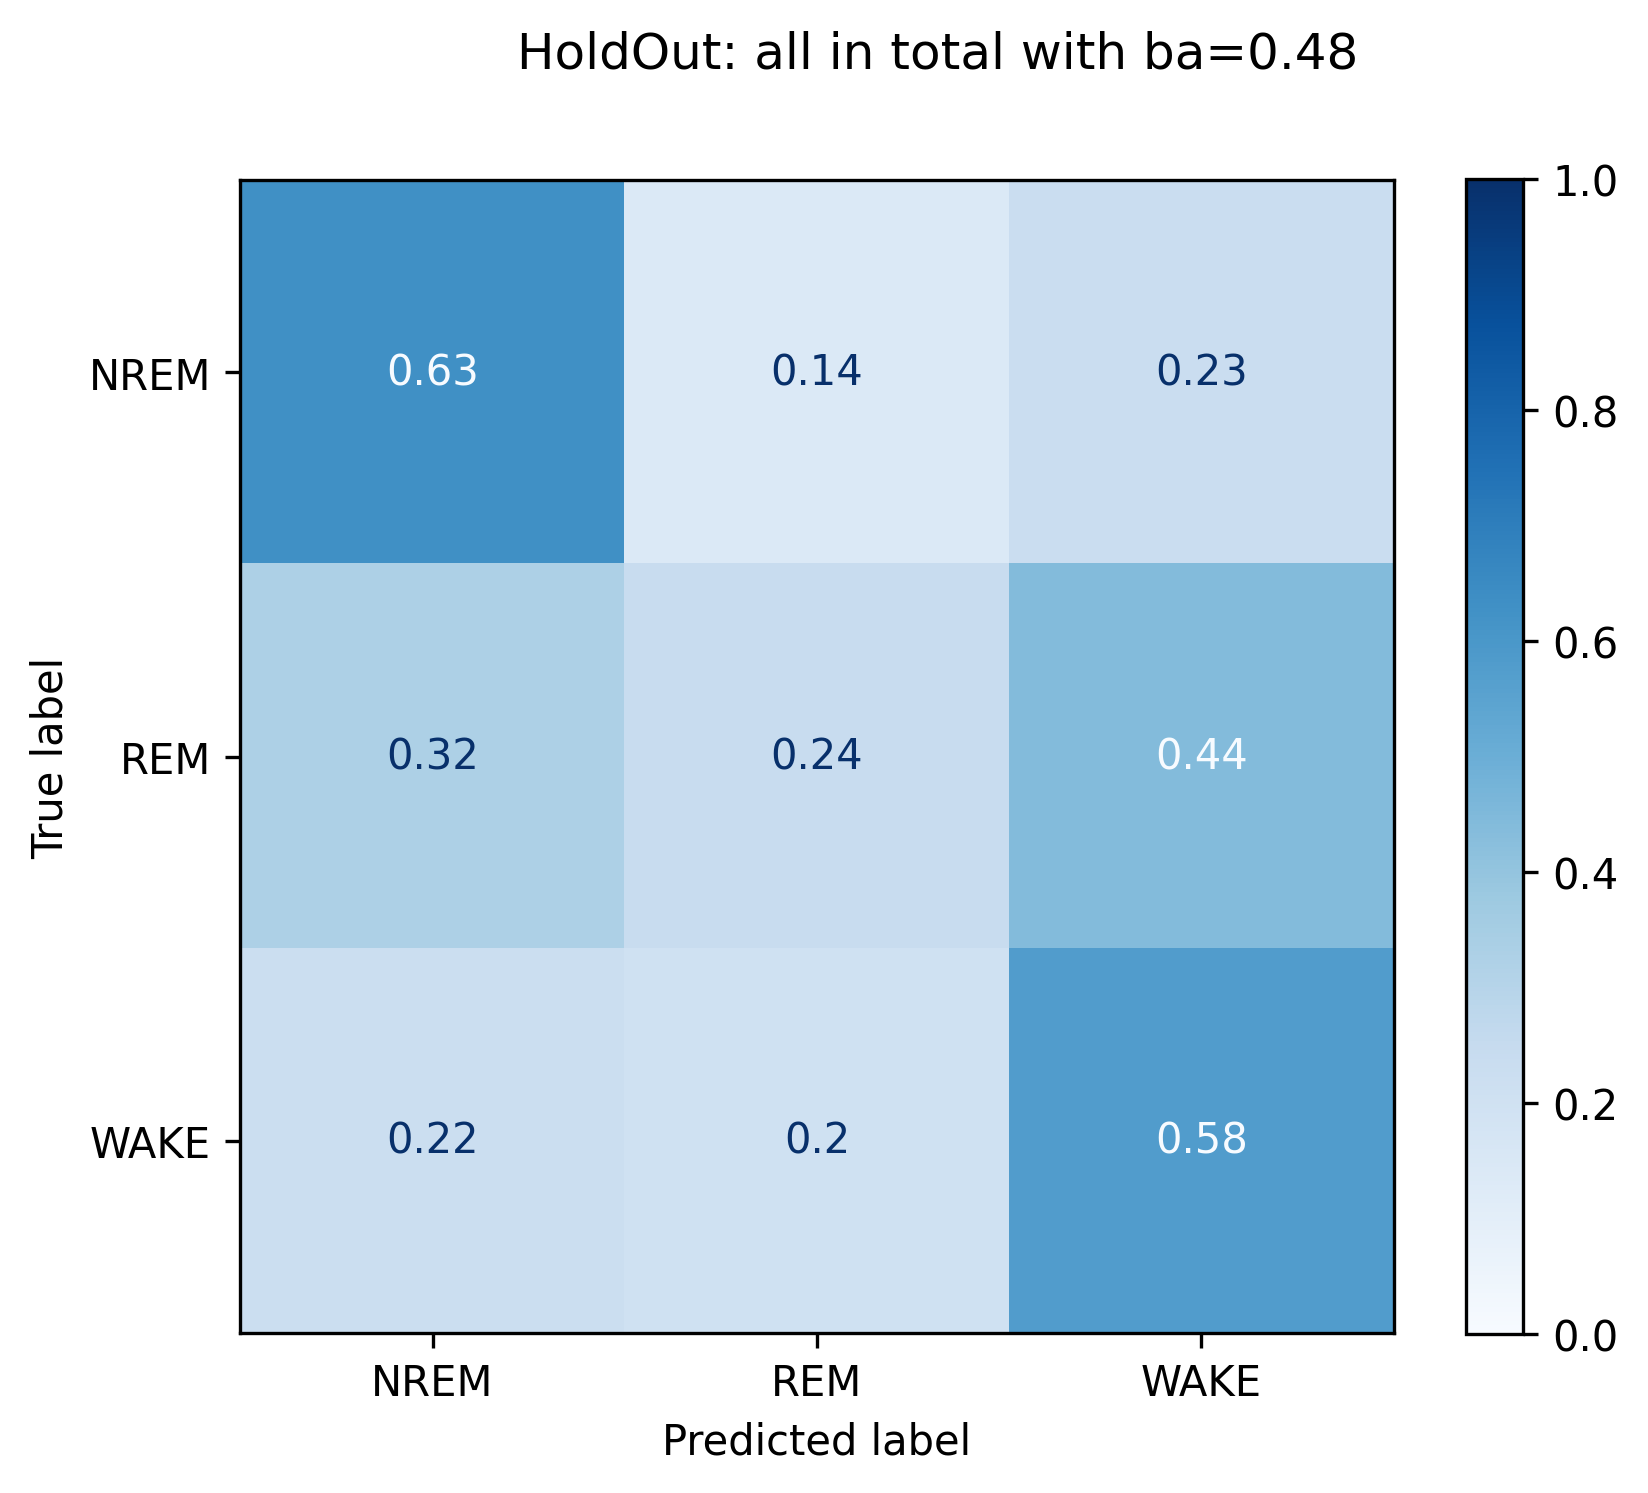

In [51]:
#Visualize individual ones
for matrix in res_cms:
    get_mean_cms_visual({"combo": res_cms[matrix]}, train_condensed, f"HoldOut", subplot_kwargs={'figsize':(6.2,5), 'dpi':300}, 
                        addon_text=False, prev_group_by_anim=True)